# Clasificación supervisada de la popularidad musical mediante XGBoost

## Objetivo

El objetivo de este notebook es desarrollar y evaluar un modelo de clasificación supervisada capaz de predecir la categoría de popularidad de una canción a partir de sus características musicales.

Para ello, se utilizará el algoritmo XGBoost (Extreme Gradient Boosting), un método de ensamblaje basado en árboles de decisión que construye modelos de manera secuencial. Cada nuevo árbol busca corregir los errores cometidos por los modelos anteriores mediante la optimización de una función de pérdida.

El análisis contempla las siguientes etapas:

- Carga de los datasets de entrenamiento y prueba.
- Separación de las variables predictoras y la variable objetivo.
- Búsqueda de hiperparámetros mediante validación cruzada estratificada.
- Entrenamiento del modelo XGBoost con los mejores hiperparámetros encontrados.
- Evaluación del rendimiento durante la búsqueda de hiperparámetros.
- Evaluación final sobre el conjunto de prueba.
- Análisis de las matrices de confusión.
- Identificación de las características con mayor importancia para el modelo.

La variable objetivo será `popularity_category`, que representa la categoría de popularidad asignada a cada canción.

In [21]:
import pandas as pd
from math import comb
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

from xgboost import XGBClassifier

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    LeavePOut,
    GridSearchCV,
    RandomizedSearchCV,
    cross_validate,
    train_test_split
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

"""
En caso de que Python no encuentre en la ruta los otros directorios,
ejecutar esta configuración
"""

sys.path.append(os.path.abspath(".."))


# CONSIDERACIÓN: Si los hiperparámetros ya están encontrados, 
# la variable ENCONTRADO debe manterner el valor True o en False
# en caso de que se deban encontrar.

ENCONTRADO = True

---

## Carga de los datasets de entrenamiento y prueba

Se cargan dos datasets previamente preprocesados:

- **Conjunto de entrenamiento:** se utiliza para buscar los mejores hiperparámetros y ajustar el modelo.
- **Conjunto de prueba:** se reserva para evaluar el rendimiento final del modelo sobre observaciones que no participan en la búsqueda ni en el entrenamiento.

Ambos conjuntos deben mantener la misma estructura de variables predictoras, incluyendo el mismo orden y las mismas transformaciones aplicadas previamente.

Finalmente, se muestran las primeras filas de cada dataset para verificar su carga y observar la estructura de los datos.

In [2]:
data_train = pd.read_csv(
    "../../../dataset/Spotify_train_preprocesado_clasificacion.csv"
)

data_test = pd.read_csv(
    "../../../dataset/Spotify_test_preprocesado_clasificacion.csv"
)

df_train = data_train.copy()
df_test = data_test.copy()

print("Dataset de entrenamiento:")
display(df_train.head())

print("\nDataset de prueba:")
display(df_test.head())

Dataset de entrenamiento:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity_category
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.360656,0.407609,0.005418,...,-0.557598,0.751125,-0.804229,0.532848,-0.562123,-0.436477,1.542740,-0.147610,-0.695300,1
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.360656,0.100464,-0.034422,...,-0.017461,0.751125,-0.785413,0.623235,-0.606882,-0.678120,1.183864,0.437714,-0.191994,0
2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.927115,-1.881489,0.216573,...,0.430609,0.751125,-0.519639,-0.618079,-0.580263,-0.985860,-1.305115,0.437984,0.625209,2
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.360656,1.746296,0.336094,...,0.571210,-1.331337,-0.500823,-0.710274,-0.606882,-0.635477,-0.506326,0.064335,-0.879964,0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,-0.360656,0.726344,-1.795371,...,-2.390784,-1.331337,1.124396,1.430692,1.793755,-0.671013,1.195440,2.664353,-0.772929,2



Dataset de prueba:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity_category
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.927115,-1.452645,-1.914892,...,-2.318107,0.751125,-0.700742,1.813330,1.793755,-0.700153,-1.619613,-0.133029,1.330330,0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,1.798453,0.626930,...,1.478109,0.751125,0.865678,-0.675324,-0.606764,1.390062,1.450127,-0.406397,-0.528812,0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,0.639416,0.224541,...,0.842404,0.751125,-0.199770,-0.940037,-0.606785,-0.724317,1.303489,2.353574,-0.550148,0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,-1.648427,-0.067596,0.754419,...,0.438615,0.751125,2.126046,1.707878,-0.606882,2.409939,0.292462,-1.350621,-1.566635,1
4,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.927115,0.830657,1.093063,...,1.257701,0.751125,-0.380872,-0.942719,1.793755,-1.048403,1.006355,0.096426,1.158399,0


---

## Separación de variables predictoras y variable objetivo

Se separan las variables utilizadas para realizar las predicciones de la variable que se desea estimar.

- **X_train:** características musicales del conjunto de entrenamiento.
- **y_train:** categorías de popularidad correspondientes al conjunto de entrenamiento.
- **X_test:** características musicales del conjunto de prueba.
- **y_test:** categorías reales de popularidad del conjunto de prueba.

La variable `popularity_category` se excluye de las variables predictoras para evitar que el modelo utilice directamente la respuesta que debe aprender a predecir.

Se utilizan directamente las categorías codificadas presentes en los datasets, sin aplicar transformaciones adicionales.

**Requisito de XGBoost:** en problemas multiclase, las etiquetas deben estar representadas por números enteros consecutivos desde cero (0, 1, 2, ...). Se asume que esta condición ya se cumple en los datos proporcionados.

In [3]:
# Separación de variables predictoras y objetivo
X_train = df_train.drop(
    columns=["popularity_category"]
)

y_train = df_train["popularity_category"]

X_test = df_test.drop(
    columns=["popularity_category"]
)

y_test = df_test["popularity_category"]

---

## Búsqueda de hiperparámetros mediante RandomizedSearchCV

Antes de entrenar el modelo definitivo, se realiza una búsqueda de hiperparámetros para identificar una configuración que permita mejorar el rendimiento de XGBoost.

Se utiliza `RandomizedSearchCV`, que selecciona aleatoriamente combinaciones de valores dentro de un espacio de búsqueda definido. A diferencia de una búsqueda exhaustiva, este procedimiento permite explorar distintas configuraciones sin evaluar todas las combinaciones posibles.

Se consideran los siguientes hiperparámetros:

- `n_estimators`: cantidad de árboles que se construyen secuencialmente.
- `learning_rate`: controla la contribución de cada árbol nuevo al modelo.
- `max_depth`: profundidad máxima de los árboles, relacionada con su complejidad.
- `min_child_weight`: controla la cantidad mínima de información requerida en un nodo hijo para permitir una división.
- `subsample`: proporción de observaciones utilizadas para construir cada árbol.
- `colsample_bytree`: proporción de variables predictoras utilizadas por árbol.
- `gamma`: reducción mínima de la función de pérdida requerida para realizar una división.
- `reg_alpha`: regularización L1, que puede ayudar a controlar la complejidad del modelo.
- `reg_lambda`: regularización L2, que ayuda a evitar modelos excesivamente complejos.

La búsqueda utiliza validación cruzada estratificada de cinco particiones. En cada iteración, el modelo se entrena con cuatro particiones y se evalúa con la restante, procurando mantener la distribución de las categorías.

Se utiliza **F1-Macro** como métrica principal para seleccionar la mejor configuración, ya que asigna la misma importancia a todas las categorías de popularidad, independientemente de su frecuencia.

También se registran Accuracy, Balanced Accuracy, Precision Weighted, Recall Weighted y F1 Weighted para analizar el comportamiento de las configuraciones evaluadas.

El parámetro `refit=True` permite que, una vez identificada la mejor combinación, el estimador se vuelva a entrenar automáticamente utilizando la totalidad del conjunto de entrenamiento.

**Consideración metodológica:** el conjunto de prueba no participa en la búsqueda de hiperparámetros. De esta manera, se reserva para la evaluación final de la capacidad de generalización del modelo.

In [4]:
# Configuración de la validación cruzada
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Modelo base de XGBoost
xgb_base = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=1
)

# Espacio de búsqueda de hiperparámetros
param_distributions = {
    "n_estimators": [200, 250, 300],
    "learning_rate": [0.05, 0.1],
    "max_depth": [3, 5],
    "min_child_weight": [1, 3],
    "subsample": [0.8, 1.0],
    "colsample_bytree": [0.8, 1.0],
    "gamma": [0, 0.1]
}

# Métricas utilizadas durante la búsqueda
scoring = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

---

## Busqueda de hiperparámetros con RandomSearch

In [5]:
if ENCONTRADO == False:
    random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_distributions,
    n_iter=12,
    scoring=scoring,
    refit="f1_macro",
    cv=cv,
    verbose=1,
    random_state=42,
    n_jobs=-1,
    return_train_score=True
)

    random_search.fit(X_train, y_train)

---

## Resultados de la búsqueda de hiperparámetros con RandomSearch

Una vez finalizada la búsqueda, se identifica la combinación de hiperparámetros con RandomSearch que obtuvo el mejor resultado promedio de F1-Macro durante la validación cruzada.

Se presentan los mejores parámetros encontrados y las métricas obtenidas por dicha configuración.

Además, se muestra una tabla con las diez mejores combinaciones evaluadas, ordenadas según su F1-Macro promedio.

La desviación estándar permite observar la variabilidad del rendimiento entre las cinco particiones. Un valor menor indica resultados más consistentes entre las particiones evaluadas.

In [6]:
if ENCONTRADO == False:
    print("Mejores hiperparámetros encontrados con RandomSearch:")

    for parametro, valor in random_search.best_params_.items():
        print(f"{parametro}: {valor}")

    print(
        f"\nMejor F1-Macro promedio: "
        f"{random_search.best_score_:.4f}"
    )

    # Obtener resultados de todas las configuraciones evaluadas
    resultados_busqueda = pd.DataFrame(random_search.cv_results_)

    columnas_resultados = [
        "rank_test_f1_macro",
        "mean_test_accuracy",
        "std_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_f1_weighted",
        "mean_test_f1_macro",
        "std_test_f1_macro",
        "params"
    ]

    resultados_ordenados = resultados_busqueda[
        columnas_resultados
    ].sort_values(
        by="rank_test_f1_macro"
    )

    print("\nTop 10 configuraciones evaluadas:")

    display(resultados_ordenados.head(10))

---

## Busqueda de hiperparámetros con GridSearch

In [7]:
if ENCONTRADO == False:
    grid_search = GridSearchCV(
        estimator=xgb_base,
        param_grid=param_distributions,
        scoring=scoring,
        refit="f1_macro",
        cv=cv,
        verbose=1,
        n_jobs=-1,
        return_train_score=True
    )

    grid_search.fit(X_train, y_train)

In [8]:
if ENCONTRADO == False:
    print("Mejores hiperparámetros encontrados con GridSearch:")

    for parametro, valor in grid_search.best_params_.items():
        print(f"{parametro}: {valor}")

    print(
        f"\nMejor F1-Macro promedio: "
        f"{grid_search.best_score_:.4f}"
    )

    # Obtener resultados de todas las configuraciones evaluadas
    resultados_busqueda = pd.DataFrame(grid_search.cv_results_)

    columnas_resultados = [
        "rank_test_f1_macro",
        "mean_test_accuracy",
        "std_test_accuracy",
        "mean_test_balanced_accuracy",
        "mean_test_f1_weighted",
        "mean_test_f1_macro",
        "std_test_f1_macro",
        "params"
    ]

    resultados_ordenados = resultados_busqueda[
        columnas_resultados
    ].sort_values(
        by="rank_test_f1_macro"
    )

    print("\nTop 10 configuraciones evaluadas:")

    display(resultados_ordenados.head(10))

---

## Entrenamiento del modelo XGBoost definitivo

Después de completar la búsqueda de hiperparámetros, se recupera el mejor estimador mediante `best_estimator_`.

Gracias a `refit=True`, este modelo ya fue ajustado automáticamente con la totalidad del conjunto de entrenamiento utilizando la mejor combinación de hiperparámetros encontrada.

Por tanto, no es necesario volver a ejecutar `fit()` sobre el mismo conjunto de entrenamiento.

El modelo definitivo se utilizará para generar predicciones sobre el conjunto de prueba y analizar su capacidad de generalización.

In [9]:
if ENCONTRADO == False:
    xgb_model = grid_search.best_estimator_

    print("Modelo XGBoost seleccionado:")
    print(xgb_model)

---

## Evaluación final del modelo sobre el conjunto de prueba

Se generan predicciones para las observaciones de `X_test`.

Las categorías predichas se comparan con los valores reales de `y_test` mediante las mismas métricas utilizadas durante la búsqueda de hiperparámetros.

Esta evaluación permite medir la capacidad de generalización del modelo sobre datos que no participaron en la selección de hiperparámetros ni en el entrenamiento final.

También se genera un reporte de clasificación que presenta, para cada categoría de popularidad, su precisión, recall, F1-score y cantidad de observaciones.

La comparación entre los resultados de validación cruzada y los del conjunto de prueba permite identificar posibles diferencias de rendimiento. Estas diferencias deben interpretarse considerando la distribución de las clases y el tamaño de los conjuntos evaluados.

In [10]:
if ENCONTRADO == False:
    y_pred_xgb = xgb_model.predict(X_test)

    print("Resultados de XGBoost en el conjunto de prueba:")

    print(f"Accuracy: {accuracy_score(y_test, y_pred_xgb):.4f}")

    print(
        f"Balanced Accuracy: "
        f"{balanced_accuracy_score(y_test, y_pred_xgb):.4f}"
    )

    print(
        f"Precision: "
        f"{precision_score(y_test, y_pred_xgb, average='weighted', zero_division=0):.4f}"
    )

    print(
        f"Recall: "
        f"{recall_score(y_test, y_pred_xgb, average='weighted', zero_division=0):.4f}"
    )

    print(
        f"F1-Weighted: "
        f"{f1_score(y_test, y_pred_xgb, average='weighted', zero_division=0):.4f}"
    )

    print(
        f"F1-Macro: "
        f"{f1_score(y_test, y_pred_xgb, average='macro', zero_division=0):.4f}"
    )

    print("\nReporte de clasificación:")

    print(
        classification_report(
            y_test,
            y_pred_xgb,
            zero_division=0
        )
    )

---

## Análisis de las matrices de confusión

Se construyen dos matrices de confusión para examinar con mayor detalle los aciertos y errores del modelo.

**Matriz de confusión en cantidades**

Muestra el número de observaciones correspondientes a cada combinación de categoría real y categoría predicha. La diagonal principal representa las predicciones correctas, mientras que los valores fuera de ella representan errores de clasificación.

**Matriz de confusión normalizada**

Presenta los resultados como proporciones respecto del total de observaciones de cada categoría real. Esta normalización permite comparar el comportamiento del modelo entre clases de diferentes tamaños.

En ambas matrices:

- Las filas representan las categorías reales.
- Las columnas representan las categorías predichas.
- La diagonal principal permite identificar el porcentaje o la cantidad de aciertos por categoría.
- Los valores fuera de la diagonal muestran qué categorías tiende a confundir el modelo.

Este análisis permite determinar si XGBoost distingue adecuadamente las categorías de popularidad o si presenta dificultades para diferenciar categorías cercanas.

In [11]:
if ENCONTRADO == False:
    etiquetas = xgb_model.classes_

    matriz = confusion_matrix(
        y_test,
        y_pred_xgb,
        labels=etiquetas
    )

    matriz_normalizada = confusion_matrix(
        y_test,
        y_pred_xgb,
        labels=etiquetas,
        normalize="true"
    )

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))

    sns.heatmap(
        matriz,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=etiquetas,
        yticklabels=etiquetas,
        ax=axes[0]
    )

    axes[0].set_title("Matriz de confusión - Cantidades")
    axes[0].set_xlabel("Categoría predicha")
    axes[0].set_ylabel("Categoría real")

    sns.heatmap(
        matriz_normalizada,
        annot=True,
        fmt=".1%",
        cmap="Blues",
        vmin=0,
        vmax=1,
        xticklabels=etiquetas,
        yticklabels=etiquetas,
        ax=axes[1]
    )

    axes[1].set_title("Matriz de confusión - Porcentajes")
    axes[1].set_xlabel("Categoría predicha")
    axes[1].set_ylabel("Categoría real")

    for ax in axes:
        ax.tick_params(axis="x", rotation=45)
        ax.tick_params(axis="y", rotation=0)

    plt.suptitle(
        "Evaluación de XGBoost",
        fontsize=15,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

---

## Importancia de las variables

Se examina la importancia de las características utilizadas por XGBoost para construir sus árboles de decisión.

La importancia permite identificar qué variables contribuyen en mayor medida a las decisiones del modelo, de acuerdo con el criterio de importancia proporcionado por XGBoost.

Se ordenan las características de mayor a menor importancia y se presentan las cinco primeras, junto con una visualización de las quince variables más relevantes.

**Consideración:** la importancia de variables describe la contribución dentro del modelo entrenado, pero no implica una relación causal entre una característica musical y la popularidad de una canción.

In [12]:
if ENCONTRADO == False:
    importancias = pd.DataFrame({
    "feature": X_train.columns,
    "importance": xgb_model.feature_importances_
    })

    importancias = importancias.sort_values(
        by="importance",
        ascending=False
    )

    print("Top 5 características más importantes:")

    display(importancias.head(5))

In [13]:
if ENCONTRADO == False:
    plt.figure(figsize=(10, 6))

    sns.barplot(
        data=importancias.head(15),
        x="importance",
        y="feature"
    )

    plt.title(
        "Top 15 características más importantes - XGBoost",
        fontsize=14,
        fontweight="bold"
    )
    plt.xlabel("Importancia")
    plt.ylabel("Característica")
    plt.tight_layout()
    plt.show()

---

# Validación cruzada de los 3 modelos de XGBoost desarrollados

---

## Configuración de hiperparámetros y muestra para LeavePOut

Se definen dos diccionarios con las configuraciones de hiperparámetros obtenidas previamente:

- **`hyperparams_grid`:** contiene los valores seleccionados mediante la búsqueda GridSearchCV.
- **`hyperparams_random`:** contiene los valores seleccionados mediante RandomizedSearchCV.

Estas configuraciones se utilizarán posteriormente para construir dos modelos XGBoost optimizados y compararlos con el modelo base.

Además, se prepara una muestra estratificada de 100 observaciones a partir del conjunto de entrenamiento. La estratificación utiliza `y_train` para conservar aproximadamente la distribución original de las categorías en la muestra.

Esta reducción se aplica exclusivamente a LeavePOut, debido al elevado número de combinaciones que genera este método cuando se utiliza sobre conjuntos de datos grandes. Se fija `random_state=42` para que la selección de observaciones sea reproducible.

Finalmente, se configura `LeavePOut(p=2)`. En cada iteración, dos observaciones se reservan para prueba y las restantes se utilizan para entrenar el modelo.


In [23]:
hyperparams_grid = {
    "colsample_bytree": 1.0,
    "gamma": 0.1,
    "learning_rate": 0.1,
    "max_depth": 5,
    "min_child_weight": 1,
    "n_estimators": 300,
    "subsample": 0.8
}

hyperparams_random = {
    "colsample_bytree": 1.0,
    "gamma": 0.1,
    "learning_rate": 0.1,
    "max_depth": 5,
    "min_child_weight": 3,
    "n_estimators": 300,
    "subsample": 0.8,
    "reg_lambda": 3,
    "reg_alpha": 0
}

# Selección de una muestra estratificada
X_lpo, _, y_lpo, _ = train_test_split(
    X_train,
    y_train,
    train_size=100,
    stratify=y_train,
    random_state=42
)

# Configuración de LeavePOut
cv_leave_p_out = LeavePOut(p=2)

---

## Construcción de los tres modelos XGBoost

Se instancian tres clasificadores XGBoost para comparar distintas configuraciones:

- **XGBoost base:** utiliza los parámetros generales definidos para el problema multiclase, sin incorporar la configuración optimizada.
- **XGBoost con parámetros de GridSearchCV:** utiliza los valores almacenados en `hyperparams_grid`.
- **XGBoost con parámetros de RandomizedSearchCV:** utiliza los valores almacenados en `hyperparams_random`.

Los tres modelos comparten `objective="multi:softprob"`, apropiado para clasificación multiclase, y `eval_metric="mlogloss"` como métrica interna de evaluación.

Se establece `random_state=42` para favorecer la reproducibilidad y `n_jobs=1` para limitar el paralelismo interno de cada clasificador. Esto resulta útil al ejecutar las validaciones en paralelo mediante `cross_validate`.

En esta sección se construyen clasificadores con las configuraciones seleccionadas previamente; la búsqueda de hiperparámetros no se ejecuta nuevamente en estas celdas.


In [15]:
# Modelo XGBoost base, sin hiperparámetros optimizados
xgb_base = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=1
)

# Modelo XGBoost optimizado con GridSearchCV
xgb_grid_model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=1,
    **hyperparams_grid
)

# Modelo XGBoost optimizado con RandomizedSearchCV
xgb_random_model = XGBClassifier(
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=1,
    **hyperparams_random
)

---

## Configuración de los métodos de validación cruzada

Se definen dos estrategias de validación cruzada, ambas con cinco particiones y mezcla aleatoria de las observaciones:

- **KFold:** divide el conjunto de datos en cinco particiones. En cada iteración, cuatro se utilizan para entrenar y una para evaluar. No considera la distribución de las clases al construir las particiones.
- **StratifiedKFold:** también utiliza cinco particiones, pero procura conservar en cada una la proporción de categorías presente en el conjunto completo.

En ambos casos, `shuffle=True` permite mezclar las observaciones antes de generar las particiones y `random_state=42` permite reproducir la división.


In [16]:
# KFold
cv_kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# StratifiedKFold
cv_stratified = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Validación cruzada KFold

Se evalúan los tres clasificadores mediante la estrategia KFold, utilizando el conjunto completo de entrenamiento (`X_train` y `y_train`).

La función `cross_validate` realiza el ciclo de entrenamiento y evaluación para cada partición. El procedimiento se aplica por separado al modelo base y a los dos modelos con hiperparámetros seleccionados.

El argumento `scoring=scoring` indica las métricas que se calculan en cada partición, mientras que `n_jobs=-1` permite distribuir las tareas entre los procesadores disponibles.

Los resultados de cada ejecución se almacenan en diccionarios independientes para facilitar su posterior comparación.


In [17]:
# Validación KFold - XGBoost base
resultados_base_kfold = cross_validate(
    xgb_base,
    X_train,
    y_train,
    cv=cv_kfold,
    scoring=scoring,
    n_jobs=-1
)

# Validación KFold - GridSearchCV
resultados_grid_kfold = cross_validate(
    xgb_grid_model,
    X_train,
    y_train,
    cv=cv_kfold,
    scoring=scoring,
    n_jobs=-1
)

# Validación KFold - RandomizedSearchCV
resultados_random_kfold = cross_validate(
    xgb_random_model,
    X_train,
    y_train,
    cv=cv_kfold,
    scoring=scoring,
    n_jobs=-1
)

## Validación cruzada StratifiedKFold

Se repite la evaluación de los tres clasificadores utilizando StratifiedKFold y el conjunto completo de entrenamiento.

A diferencia de KFold, esta estrategia procura mantener la proporción de las categorías en cada partición. Esta característica es relevante en problemas de clasificación multiclase, especialmente cuando las categorías no tienen la misma frecuencia.

Se mantienen las mismas métricas y configuraciones de ejecución utilizadas en KFold. De esta manera, es posible comparar el comportamiento de los modelos bajo ambas estrategias de particionamiento.


In [18]:
# Validación StratifiedKFold - XGBoost base
resultados_base_stratified = cross_validate(
    xgb_base,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring=scoring,
    n_jobs=-1
)

# Validación StratifiedKFold - GridSearchCV
resultados_grid_stratified = cross_validate(
    xgb_grid_model,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring=scoring,
    n_jobs=-1
)

# Validación StratifiedKFold - RandomizedSearchCV
resultados_random_stratified = cross_validate(
    xgb_random_model,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring=scoring,
    n_jobs=-1
)

## Cálculo de la cantidad de particiones de LeavePOut

Antes de ejecutar LeavePOut, se calcula la cantidad de combinaciones que generará la configuración seleccionada.

La cantidad de particiones se obtiene mediante la combinación:

\[
N = \binom{n}{p} = \frac{n!}{p!(n-p)!}
\]

Donde `n` corresponde al número de observaciones de la muestra (`X_lpo`) y `p` al número de observaciones reservadas para prueba en cada iteración.

Con una muestra de 100 observaciones y `p=2`, LeavePOut genera 4.950 particiones por modelo. Este cálculo permite dimensionar el costo computacional antes de ejecutar las evaluaciones.


In [24]:
# Cantidad de observaciones de la muestra
n = len(X_lpo)

# Cantidad de particiones LeavePOut
cantidad_particiones = comb(n, 2)

print(f"Observaciones seleccionadas: {n}")
print(f"Cantidad de particiones: {cantidad_particiones:,}")

Observaciones seleccionadas: 100
Cantidad de particiones: 4,950


## Validación cruzada LeavePOut

Se evalúan los tres modelos utilizando LeavePOut sobre la muestra estratificada de 100 observaciones (`X_lpo` y `y_lpo`).

En cada iteración, dos observaciones se reservan para prueba y las otras 98 se utilizan para entrenar el clasificador. El proceso recorre todas las combinaciones posibles de dos observaciones, generando 4.950 iteraciones por modelo.

Se utiliza un conjunto de métricas que incluye Accuracy, Balanced Accuracy, Precision Weighted, Recall Weighted, F1 Weighted y F1-Macro. Estas métricas permiten observar el rendimiento desde distintas perspectivas, tanto globales como sensibles al comportamiento de las categorías.

Los resultados se almacenan por separado para cada modelo y se utilizarán en la tabla comparativa.

**Consideración:** LeavePOut se ejecuta sobre una muestra de 100 observaciones, mientras que KFold y StratifiedKFold se ejecutan sobre el conjunto completo de entrenamiento. Por esta diferencia, los resultados de LeavePOut deben interpretarse como un análisis complementario y no como una comparación directamente equivalente a las otras dos estrategias.


In [26]:
# Métrica para LeavePOut
scoring_lpo = {
    "accuracy": "accuracy",
    "balanced_accuracy": "balanced_accuracy",
    "precision_weighted": "precision_weighted",
    "recall_weighted": "recall_weighted",
    "f1_weighted": "f1_weighted",
    "f1_macro": "f1_macro"
}

# Validación LeavePOut - XGBoost base
resultados_base_lpo = cross_validate(
    xgb_base,
    X_lpo,
    y_lpo,
    cv=cv_leave_p_out,
    scoring=scoring_lpo,
    n_jobs=-1
)

# Validación LeavePOut - GridSearchCV
resultados_grid_lpo = cross_validate(
    xgb_grid_model,
    X_lpo,
    y_lpo,
    cv=cv_leave_p_out,
    scoring=scoring_lpo,
    n_jobs=-1
)

# Validación LeavePOut - RandomizedSearchCV
resultados_random_lpo = cross_validate(
    xgb_random_model,
    X_lpo,
    y_lpo,
    cv=cv_leave_p_out,
    scoring=scoring_lpo,
    n_jobs=-1
)

## Consolidación y comparación de los resultados

Se agrupan los resultados de las nueve evaluaciones en un diccionario: los tres modelos evaluados mediante KFold, los tres mediante StratifiedKFold y los tres mediante LeavePOut.

Posteriormente, se recorre cada resultado para construir una fila por combinación de modelo y método de validación. Para cada métrica disponible se calcula:

- **Promedio:** representa el rendimiento medio obtenido en las particiones.
- **Desviación estándar:** describe la variabilidad de la métrica entre las particiones evaluadas.

La tabla incluye Accuracy y, cuando están disponibles, Balanced Accuracy, Precision Weighted, Recall Weighted, F1 Weighted y F1-Macro.

Finalmente, se crea `df_resultados_cv`, un DataFrame que reúne los resultados y permite realizar comparaciones y visualizaciones posteriores.


In [27]:

# Diccionario con los resultados de las validaciones cruzadas
validaciones = {
    "XGBoost Base - KFold": resultados_base_kfold,
    "XGBoost GridSearchCV - KFold": resultados_grid_kfold,
    "XGBoost RandomizedSearchCV - KFold": resultados_random_kfold,

    "XGBoost Base - StratifiedKFold": resultados_base_stratified,
    "XGBoost GridSearchCV - StratifiedKFold": resultados_grid_stratified,
    "XGBoost RandomizedSearchCV - StratifiedKFold": resultados_random_stratified,

    "XGBoost Base - LeavePOut": resultados_base_lpo,
    "XGBoost GridSearchCV - LeavePOut": resultados_grid_lpo,
    "XGBoost RandomizedSearchCV - LeavePOut": resultados_random_lpo
}

# Lista para almacenar los resultados
resultados_cv = []

# Recorrer los resultados de cada validación
for nombre, resultado in validaciones.items():

    fila = {
        "Modelo": nombre,
        "Accuracy": resultado["test_accuracy"].mean(),
        "Desviación Accuracy": resultado["test_accuracy"].std()
    }

    # Incorporar las demás métricas cuando estén disponibles
    for metrica in [
        "balanced_accuracy",
        "precision_weighted",
        "recall_weighted",
        "f1_weighted",
        "f1_macro"
    ]:

        clave = f"test_{metrica}"

        if clave in resultado:
            fila[metrica] = resultado[clave].mean()
            fila[f"Desviación {metrica}"] = resultado[clave].std()

    resultados_cv.append(fila)

# Crear DataFrame comparativo
df_resultados_cv = pd.DataFrame(resultados_cv)

# Mostrar resultados
display(df_resultados_cv.round(4))


,Modelo,Accuracy,Desviación Accuracy,balanced_accuracy,Desviación balanced_accuracy,precision_weighted,Desviación precision_weighted,recall_weighted,Desviación recall_weighted,f1_weighted,Desviación f1_weighted,f1_macro,Desviación f1_macro
0,XGBoost Base - KFold,0.7222,0.0037,0.7222,0.0033,0.7221,0.0036,0.7222,0.0037,0.7216,0.0037,0.7216,0.0034
1,XGBoost GridSearchCV - KFold,0.6959,0.0031,0.6959,0.0025,0.6948,0.0032,0.6959,0.0031,0.6945,0.0032,0.6945,0.0026
2,XGBoost RandomizedSearchCV - KFold,0.6936,0.0029,0.6936,0.0025,0.6923,0.0029,0.6936,0.0029,0.6921,0.0030,0.6921,0.0025
3,XGBoost Base - StratifiedKFold,0.7224,0.0028,0.7224,0.0028,0.7224,0.0028,0.7224,0.0028,0.7219,0.0028,0.7219,0.0028
4,XGBoost GridSearchCV - StratifiedKFold,0.6957,0.0028,0.6957,0.0028,0.6947,0.0028,0.6957,0.0028,0.6943,0.0028,0.6943,0.0028
5,XGBoost RandomizedSearchCV - StratifiedKFold,0.6945,0.0030,0.6945,0.0030,0.6934,0.0031,0.6945,0.0030,0.6930,0.0031,0.6930,0.0031
6,XGBoost Base - LeavePOut,0.2932,0.3188,0.2932,0.3188,0.3105,0.3642,0.2932,0.3188,0.2921,0.3249,0.2228,0.2816
7,XGBoost GridSearchCV - LeavePOut,0.2900,0.3173,0.2900,0.3173,0.3056,0.3601,0.2900,0.3173,0.2886,0.3229,0.2199,0.2793
8,XGBoost RandomizedSearchCV - LeavePOut,0.3010,0.3210,0.3010,0.3210,0.3184,0.3648,0.3010,0.3210,0.3003,0.3271,0.2294,0.2852


## Comparación gráfica de F1-Macro por método de validación

Se prepara una copia del DataFrame comparativo y se separa el nombre de cada evaluación en dos componentes: el método de validación y el tipo de modelo.

A continuación, se construye un gráfico de barras agrupadas que compara el F1-Macro promedio de los tres modelos dentro de cada método:

- KFold.
- StratifiedKFold.
- LeavePOut.

Cada grupo permite observar el rendimiento del modelo base frente a las configuraciones obtenidas mediante GridSearchCV y RandomizedSearchCV. Las etiquetas sobre las barras muestran el F1-Macro expresado como porcentaje y con dos decimales.

El eje vertical se establece entre 0 y 1, con un margen adicional para que las etiquetas sean visibles.

**Interpretación:** F1-Macro calcula el F1-score de cada categoría y luego obtiene el promedio sin ponderar por la cantidad de observaciones de cada clase. Por ello, permite observar el rendimiento considerando por igual todas las categorías.

**Consideración:** los valores de LeavePOut proceden de una muestra de 100 observaciones, mientras que KFold y StratifiedKFold utilizan el conjunto completo. Esta diferencia debe tenerse presente al interpretar el gráfico.


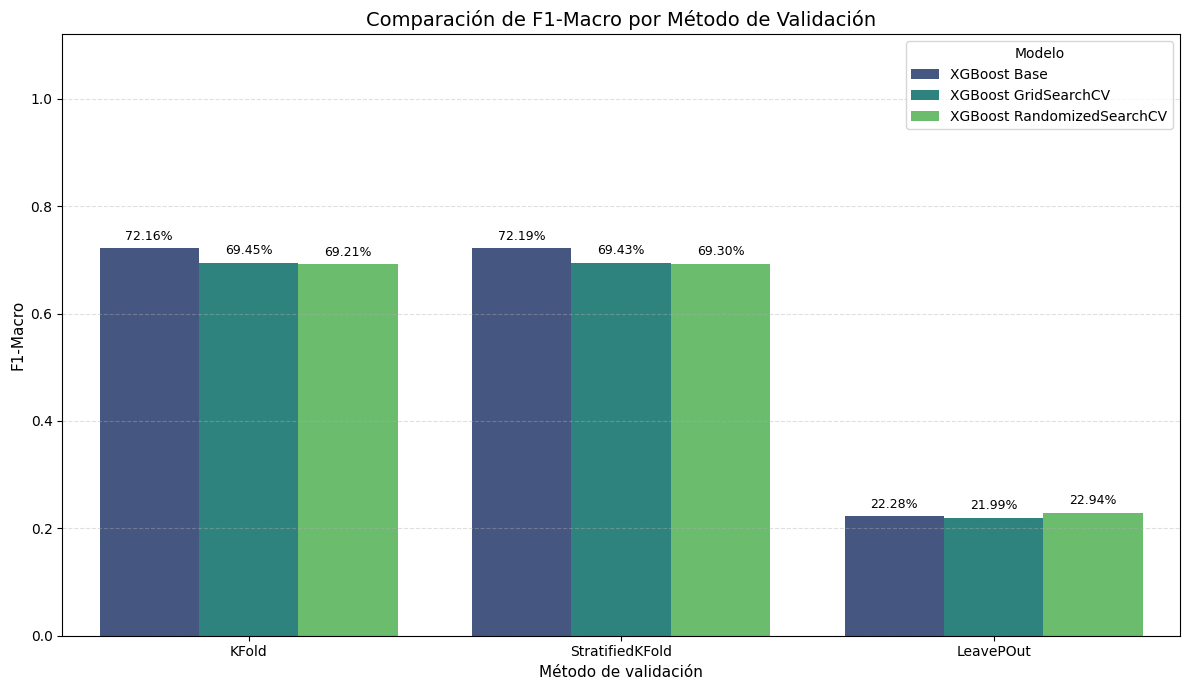

In [32]:

# Preparar los datos para la comparación
df_grafico = df_resultados_cv.copy()

df_grafico["Validación"] = df_grafico["Modelo"].str.split(" - ").str[1]
df_grafico["Tipo de modelo"] = df_grafico["Modelo"].str.split(" - ").str[0]

# Configuración del gráfico
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=df_grafico,
    x="Validación",
    y="f1_macro",
    hue="Tipo de modelo",
    order=["KFold", "StratifiedKFold", "LeavePOut"],
    hue_order=[
        "XGBoost Base",
        "XGBoost GridSearchCV",
        "XGBoost RandomizedSearchCV"
    ],
    palette="viridis"
)

# Mostrar porcentajes encima de las barras
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[f"{barra.get_height() * 100:.2f}%" for barra in container],
        padding=4,
        fontsize=9
    )

# Personalización
plt.title("Comparación de F1-Macro por Método de Validación", fontsize=14)
plt.xlabel("Método de validación", fontsize=11)
plt.ylabel("F1-Macro", fontsize=11)

plt.ylim(0, 1.12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Modelo")

plt.tight_layout()
plt.show()
